In [45]:
import pickle
import pandas as pd
import os
from pathlib import Path
from typing import List, Dict, Any, Tuple, Union, Optional

In [46]:
def load_metrics(file: Path):
    with open(file, 'rb') as f:
        metrics = pickle.load(f)
    return metrics

# metrics_results = load_metrics('/workspaces/hunavsim_ws/bags/metrics/group.pickle')

def separate_metrics(results: pd.DataFrame) -> Tuple[Dict[str,pd.DataFrame]]:
    metrics_list = results.columns 
    metrics_list = [x for x in metrics_list if x not in ['experiment', 'algorithm', 'run']]
    metrics_dict = {}
    for metric in metrics_list:
        metrics_dict[metric] = results[[metric, 'algorithm', 'experiment', 'run']]
    return metrics_dict

In [47]:
# separate_metrics(metrics_results)
# load and concatenate all metrics files in a directory
def load_metrics_files(directory: Path, metrics_keys: Optional[List[str]] = None) -> pd.DataFrame:
    metrics_files = list(directory.glob('*.pickle'))
    metrics_list = []
    for file in metrics_files:
        metrics = load_metrics(file)
        metrics_list.append(metrics)
    metrics_df = pd.concat(metrics_list)
    return metrics_df

In [48]:
metrics_results = load_metrics(Path('/workspaces/hunavsim_ws/bags/metrics/filtered/group_filtered.pickle'))
metrics_results

,path_length,cumulative_heading_changes,avg_distance_to_closest_person,minimum_distance_to_people,maximum_distance_to_people,intimate_space_intrusions,personal_space_intrusions,social_space_intrusions,public_space_intrusions,group_intimate_space_intrusions,...,avg_closest_pedestrian_velocity,social_force_on_agents,social_force_on_robot,social_work,social_work_per_second,obstacle_force_on_agents,obstacle_force_on_robot,experiment,algorithm,run
0,27.045291,2.283651,1.226802,-0.021372,3.429030,14.889800,23.347002,61.763198,0.0,0.0,...,0.022832,1676.894089,1676.894089,6613.933484,1.695011,40.640097,3439.281823,group,first_planner,1
1,28.534106,15.342640,1.007787,0.397912,3.062441,7.982152,69.905801,22.112048,0.0,0.0,...,0.015404,1834.310319,1834.310319,5262.633781,1.304570,13.403238,1914.212585,group,first_planner,2
2,29.631926,2.892867,1.250824,0.493577,3.817872,0.000000,38.108614,61.891386,0.0,0.0,...,0.036920,1261.946690,1261.946690,5764.139780,1.799045,5.769260,3417.086990,group,first_planner,3
3,24.354367,3.802827,0.889572,0.054600,3.119963,14.024201,72.634192,13.341607,0.0,0.0,...,0.024312,1592.032716,1592.032716,2740.115148,0.850175,16.105512,25.190370,group,second_planner,1
4,20.917339,1.377604,1.169747,0.403076,2.903093,4.919308,29.982500,65.098192,0.0,0.0,...,0.020722,2594.568910,2594.568910,5030.658898,0.978157,15.636716,419.594119,group,second_planner,2
5,16.300057,0.628773,0.772380,0.322363,3.253370,31.277319,44.487615,24.235066,0.0,0.0,...,0.044683,1080.131068,1080.131068,1789.842459,0.869278,5.751640,43.245124,group,second_planner,3


In [49]:
# create a table with the following format
directory = Path('/workspaces/hunavsim_ws/bags/metrics/filtered')
metrics_results = load_metrics_files(directory)
#drop run 3 for l_shaped_not_compliant
metrics_results = metrics_results[~((metrics_results['experiment'] == 'l_shaped_not_compliant_filtered') & (metrics_results['run'] == 3))]
    #           #
#experiment  algorithm  social_work
def mean_metrics(metrics: pd.DataFrame) -> pd.DataFrame:
    metrics_dict = separate_metrics(metrics)
    mean_metrics_dict = {}
    for key, value in metrics_dict.items():
        mean_metrics_dict[key] = value.groupby(['experiment', 'algorithm']).mean().reset_index()
    return mean_metrics_dict
def std_dev_metrics(metrics: pd.DataFrame) -> pd.DataFrame:
    metrics_dict = separate_metrics(metrics)
    std_dev_metrics_dict = {}
    for key, value in metrics_dict.items():
        std_dev_metrics_dict[key] = value.groupby(['experiment', 'algorithm']).std().reset_index()
    return std_dev_metrics_dict
def median_metrics(metrics: pd.DataFrame) -> pd.DataFrame:
    metrics_dict = separate_metrics(metrics)
    median_metrics_dict = {}
    for key, value in metrics_dict.items():
        median_metrics_dict[key] = value.groupby(['experiment', 'algorithm']).median().reset_index()
    return median_metrics_dict
def max_metrics(metrics: pd.DataFrame) -> pd.DataFrame:
    metrics_dict = separate_metrics(metrics)
    max_metrics_dict = {}
    for key, value in metrics_dict.items():
        max_metrics_dict[key] = value.groupby(['experiment', 'algorithm']).max().reset_index()
    return max_metrics_dict
def min_metrics(metrics: pd.DataFrame) -> pd.DataFrame:
    metrics_dict = separate_metrics(metrics)
    min_metrics_dict = {}
    for key, value in metrics_dict.items():
        min_metrics_dict[key] = value.groupby(['experiment', 'algorithm']).min().reset_index()
    return min_metrics_dict


metrics_mean = mean_metrics(metrics_results)
metrics_std_dev = std_dev_metrics(metrics_results)
metrics_median = median_metrics(metrics_results)
# metrics_mean['social_work_per_second'
#join the metrics with the results
keys = list(metrics_mean.keys())
print(keys)
keys_to_join = ['path_length', 'minimum_distance_to_people','avg_distance_to_closest_person', 'maximum_distance_to_people', 'intimate_space_intrusions', 'personal_space_intrusions', 'social_space_intrusions', 'public_space_intrusions', 'robot_on_person_collision', 'person_on_robot_collision', 'social_force_on_agents', 'social_force_on_robot', 'social_work', 'social_work_per_second', 'obstacle_force_on_agents', 'obstacle_force_on_robot']
# mean_metrics = pd.merge(metrics_mean['social_work_per_second'], metrics_mean['social_work'], on=['experiment', 'algorithm'], how='outer') 
mean_metrics = metrics_mean[keys[0]]
for key in keys_to_join:
    mean_metrics = pd.merge(mean_metrics, metrics_mean[key], on=['experiment', 'algorithm'], how='outer')
    if 'run_x' in mean_metrics.columns:
        mean_metrics.drop(columns=['run_x', 'run_y'], inplace=True)

median_metrics = metrics_median[keys[0]]
for key in keys_to_join:
    median_metrics = pd.merge(median_metrics, metrics_median[key], on=['experiment', 'algorithm'], how='outer')
    if 'run_x' in median_metrics.columns:
        median_metrics.drop(columns=['run_x', 'run_y'], inplace=True)
        
std_dev_metrics = metrics_std_dev[keys[0]]
for key in keys_to_join:
    std_dev_metrics = pd.merge(std_dev_metrics, metrics_std_dev[key], on=['experiment', 'algorithm'], how='outer')
    if 'run_x' in std_dev_metrics.columns:
        std_dev_metrics.drop(columns=['run_x', 'run_y'], inplace=True)
        

['path_length', 'cumulative_heading_changes', 'avg_distance_to_closest_person', 'minimum_distance_to_people', 'maximum_distance_to_people', 'intimate_space_intrusions', 'personal_space_intrusions', 'social_space_intrusions', 'public_space_intrusions', 'group_intimate_space_intrusions', 'group_personal_space_intrusions', 'group_social_space_intrusions', 'group_public_space_intrusions', 'robot_on_person_collision', 'person_on_robot_collision', 'time_not_moving', 'avg_robot_linear_speed', 'avg_robot_angular_speed', 'avg_acceleration', 'avg_overacceleration', 'avg_pedestrian_velocity', 'avg_closest_pedestrian_velocity', 'social_force_on_agents', 'social_force_on_robot', 'social_work', 'social_work_per_second', 'obstacle_force_on_agents', 'obstacle_force_on_robot']


In [53]:
# show only the first 3 decimals
# mean_metrics.round(2)[['experiment','algorithm','intimate_space_intrusions','personal_space_intrusions','social_space_intrusions','public_space_intrusions']]
mean_metrics.round(2)

,experiment,algorithm,path_length_x,path_length_y,minimum_distance_to_people,avg_distance_to_closest_person,maximum_distance_to_people,intimate_space_intrusions,personal_space_intrusions,social_space_intrusions,public_space_intrusions,robot_on_person_collision,person_on_robot_collision,social_force_on_agents,social_force_on_robot,social_work,social_work_per_second,obstacle_force_on_agents,obstacle_force_on_robot,run
0,group,GSCL+Nav-Fn,28.40,28.40,0.29,1.16,3.44,7.62,43.79,48.59,0.00,0.0,0.0,1591.05,1591.05,5880.24,1.60,19.94,2923.53,2.0
1,group,Nav-Fn,20.52,20.52,0.26,0.94,3.09,16.74,49.03,34.22,0.00,0.0,0.0,1755.58,1755.58,3186.87,0.90,12.50,162.68,2.0
2,l_shaped_compliant,GSCL+Nav-Fn,26.05,26.05,0.29,2.25,5.41,5.34,18.61,66.31,9.74,0.0,0.0,696.61,696.61,11226.58,4.48,454200.81,11624.48,2.0
3,l_shaped_compliant,Nav-Fn,23.60,23.60,0.05,2.01,5.45,9.13,35.31,41.07,14.50,0.0,0.0,1681.37,1681.37,16902.08,2.76,1582947.98,13821.11,2.0
4,l_shaped_not_compliant,GSCL+Nav-Fn,27.24,27.24,0.07,2.05,5.73,13.75,20.27,43.30,22.68,0.0,0.0,882.27,882.27,9137.33,3.50,152146.86,7503.12,2.0
5,l_shaped_not_compliant,Nav-Fn,20.32,20.32,-0.02,1.46,5.16,27.66,33.06,26.95,12.33,0.0,0.0,1134.55,1134.55,11261.04,4.03,294791.67,9163.88,2.0
6,split_with_two_entry_points,GSCL+Nav-Fn,65.08,65.08,0.17,1.88,4.97,7.47,21.09,68.86,2.58,0.0,0.0,2571.66,2571.66,60169.99,7.38,2116690.63,55582.37,2.0
7,split_with_two_entry_points,Nav-Fn,21.49,21.49,0.37,1.39,3.53,13.06,21.59,65.35,0.00,0.0,0.0,911.49,911.49,20267.70,7.89,1452192.04,18683.87,2.0


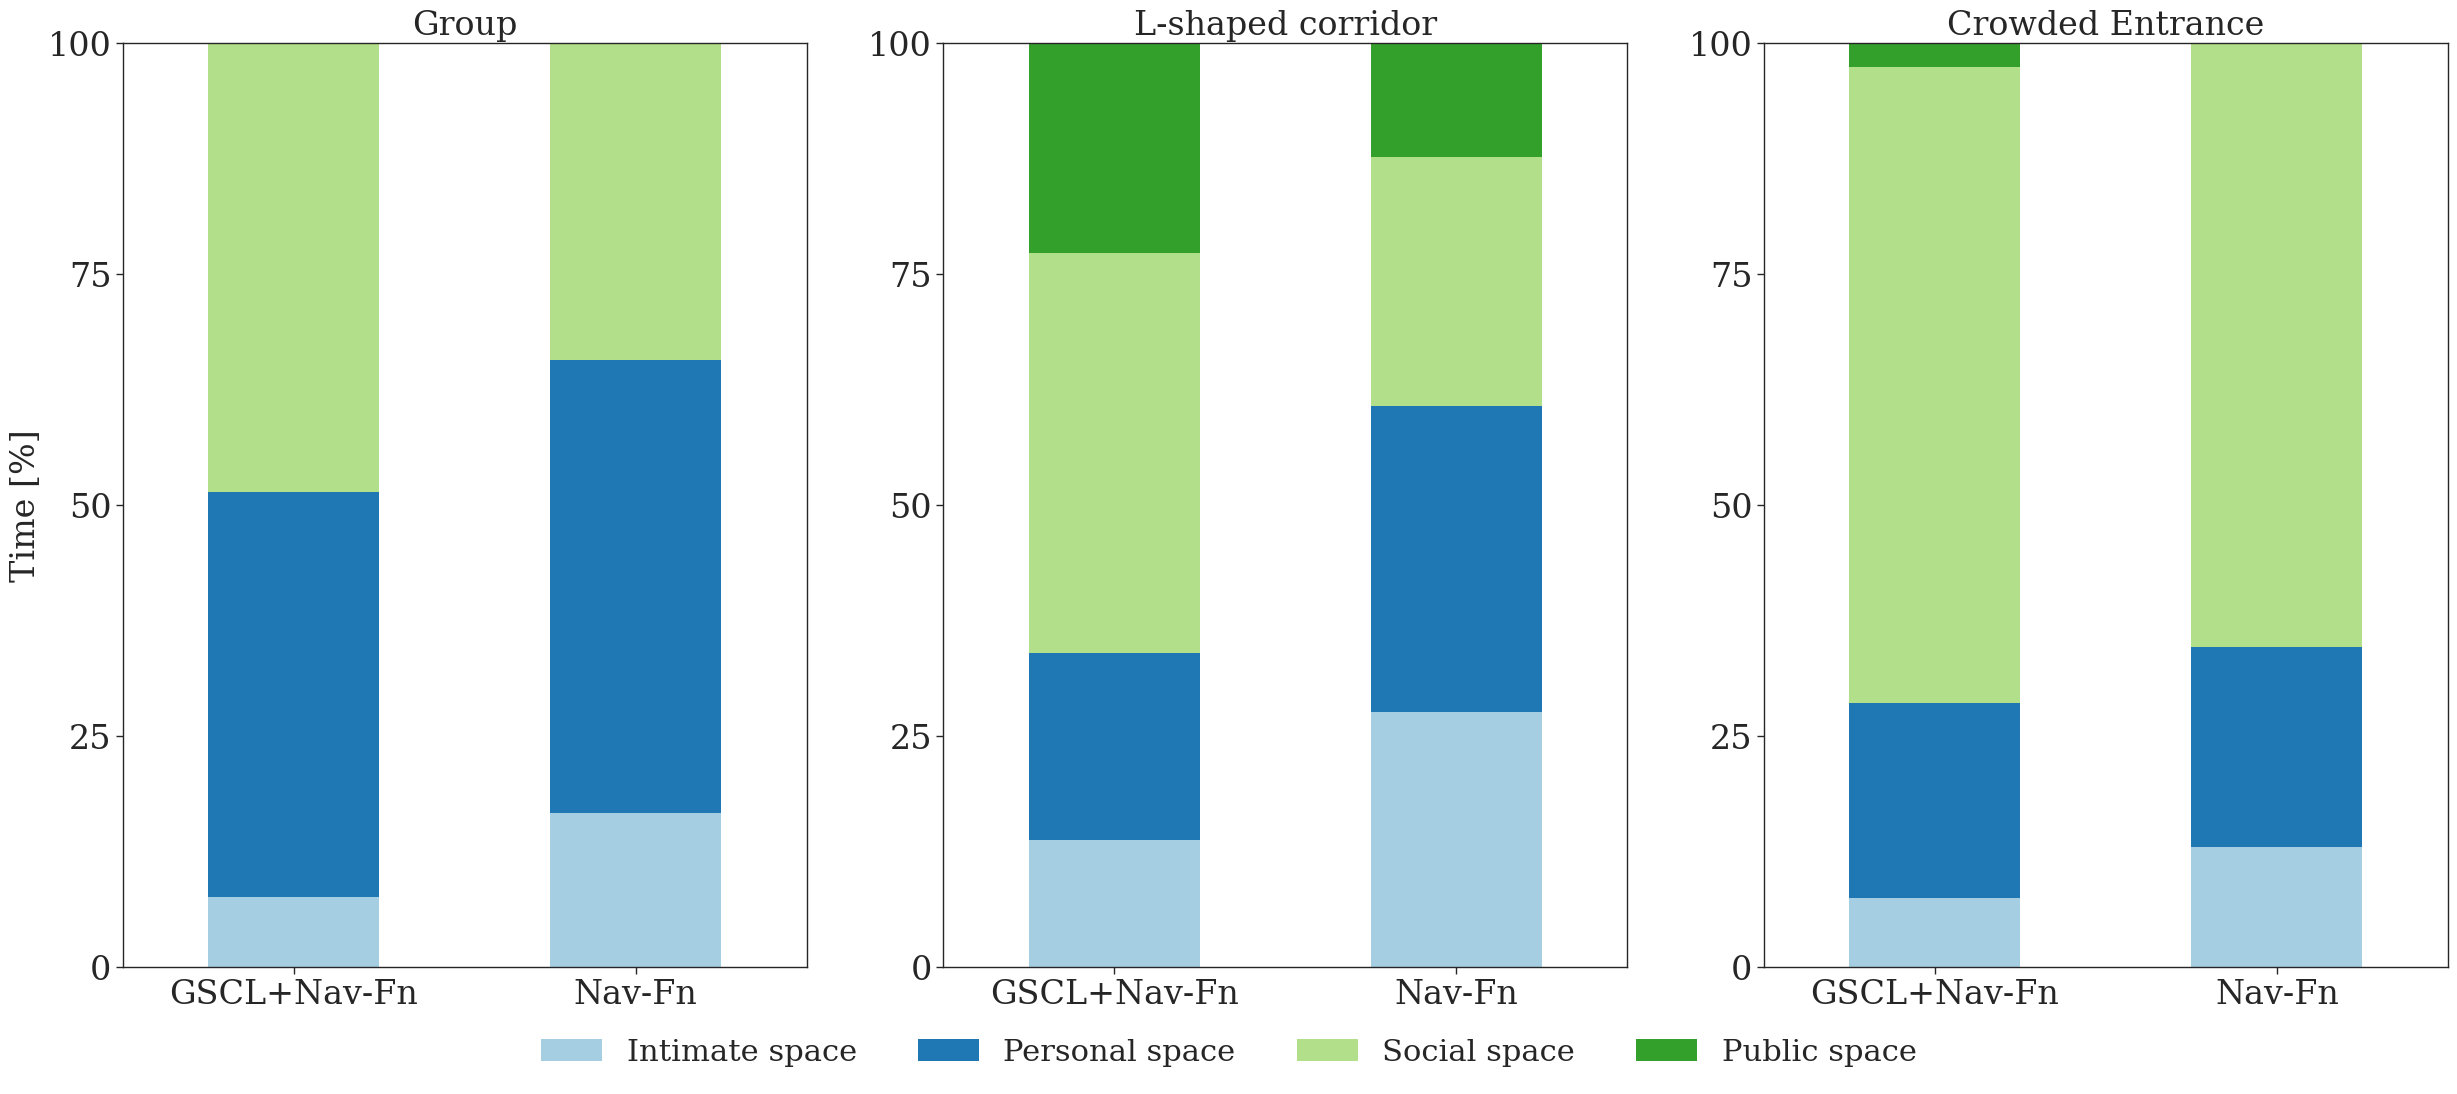

In [51]:
# instogram of the proxemic distances
import matplotlib.pyplot as plt
import seaborn as sns
# sns.set(style="whitegrid")

# print(mean_metrics['experiment'].unique())
# environments = ['group', 'l_shaped_compliant','l_shaped_not_compliant', 'split_with_two_entry_points']
environments = ['group', 'l_shaped_not_compliant', 'split_with_two_entry_points']
algorithm_names = ['GSCL+Nav-Fn', 'Nav-Fn']
environment_names = ['Group', 'L-shaped corridor', 'Crowded Entrance']
episodes_n = len(environments)

#use a style compatible with tikz plots
plt.style.use('seaborn-ticks')
sns.set_context("paper")
# use font roman
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman'] + plt.rcParams['font.serif']
# sns.set_context("talk")
# font size


# substitute the algorithm names
mean_metrics['algorithm'] = mean_metrics['algorithm'].replace('first_planner', 'GSCL+Nav-Fn')
mean_metrics['algorithm'] = mean_metrics['algorithm'].replace('second_planner', 'Nav-Fn')
rows = 1
cols = episodes_n // rows
fig, ax = plt.subplots(rows, cols, figsize=(10 * episodes_n, 12))
intrusions = ['intimate_space_intrusions', 'personal_space_intrusions', 'social_space_intrusions', 'public_space_intrusions']
for i, environment in enumerate(environments):
#   runs_df[runs_df['environment'] == i+1].plot.bar(ax=ax[i//cols, i%cols], x='method', y=intrusions, stacked=True, rot=0, color=plt.cm.get_cmap('Paired').colors)
#   mean_metrics[mean_metrics['experiment'] == environment].plot.bar(ax=ax[i//cols, i%cols], x='algorithm', y=intrusions, stacked=True, rot=0, color=plt.cm.get_cmap('Paired').colors)
#   ax[i//cols, i%cols].set_title(environment_names[i], fontsize=22)
#   ax[i//cols, i%cols].legend().remove()
#   ax[i//cols, i%cols].set_ylabel('Time [%]')
#   ax[i//cols, i%cols].set_xlabel('')
#   ax[i//cols, i%cols].set_ylim(0, 100)
#   ax[i//cols, i%cols].set_yticks([0, 25, 50, 75, 100])
    mean_metrics[mean_metrics['experiment'] == environment].plot.bar(ax=ax[i], x='algorithm', y=intrusions, stacked=True, rot=0, color=plt.cm.get_cmap('Paired').colors)
    ax[i].set_title(environment_names[i], fontsize=22)
    ax[i].legend().remove()
    # ax[i].set_ylabel('Time [%]')
    ax[i].set_xlabel('')
    ax[i].set_ylim(0, 100)
    ax[i].set_yticks([0, 25, 50, 75, 100])
    #set the y label only for the first plot
    if i == 0:
        ax[i].set_ylabel('Time [%]')
    else:
        ax[i].set_ylabel('')

  # modify font size
#   for item in ([ax[i//cols, i%cols].title, ax[i//cols, i%cols].xaxis.label, ax[i//cols, i%cols].yaxis.label] +
#              ax[i//cols, i%cols].get_xticklabels() + ax[i//cols, i%cols].get_yticklabels()):
#     item.set_fontsize(20)
    for item in ([ax[i].title, ax[i].xaxis.label, ax[i].yaxis.label] +
              ax[i].get_xticklabels() + ax[i].get_yticklabels()):
        item.set_fontsize(24)


# from matplotlib.
labels = ['Intimate space', 'Personal space', 'Social space', 'Public space']
fig.legend(labels=labels, loc='lower center', ncol=4, fontsize=22)


fig.savefig('/workspaces/hunavsim_ws/bags/metrics/plot_proxemic_distances.png', bbox_inches='tight')

In [52]:
std_dev_metrics.round(2)


,experiment,algorithm,path_length_x,path_length_y,minimum_distance_to_people,avg_distance_to_closest_person,maximum_distance_to_people,intimate_space_intrusions,personal_space_intrusions,social_space_intrusions,public_space_intrusions,robot_on_person_collision,person_on_robot_collision,social_force_on_agents,social_force_on_robot,social_work,social_work_per_second,obstacle_force_on_agents,obstacle_force_on_robot,run
0,group,first_planner,1.30,1.30,0.27,0.13,0.38,7.45,23.79,22.93,0.00,0.0,0.0,295.68,295.68,683.09,0.26,18.33,874.16,1.0
1,group,second_planner,4.04,4.04,0.18,0.20,0.18,13.39,21.69,27.29,0.00,0.0,0.0,770.35,770.35,1665.96,0.07,5.85,222.68,1.0
2,l_shaped_compliant,first_planner,4.52,4.52,0.17,0.40,1.05,4.68,6.50,13.17,16.87,0.0,0.0,610.54,610.54,11296.62,3.29,433916.34,8176.66,1.0
3,l_shaped_compliant,second_planner,5.29,5.29,0.13,0.52,1.00,1.08,21.84,24.59,3.86,0.0,0.0,1219.56,1219.56,19853.81,1.33,2119085.78,17757.29,1.0
4,l_shaped_not_compliant,first_planner,3.35,3.35,0.02,0.41,0.08,2.87,2.86,17.56,17.13,0.0,0.0,170.79,170.79,3589.24,1.14,87257.40,3267.08,1.0
5,l_shaped_not_compliant,second_planner,11.18,11.18,0.26,0.86,1.63,19.59,11.83,14.79,10.84,0.0,0.0,404.54,404.54,3768.36,0.99,339490.17,3134.55,1.0
6,split_with_two_entry_points,first_planner,13.08,13.08,0.52,0.29,0.16,11.79,12.32,18.10,2.93,0.0,0.0,922.07,922.07,84808.16,10.05,1226310.40,84474.44,1.0
7,split_with_two_entry_points,second_planner,11.88,11.88,0.38,0.38,0.71,13.64,6.24,19.79,0.00,0.0,0.0,238.10,238.10,28222.29,11.19,1292307.47,28049.08,1.0
